# Brick Sensor Interface: SPI IMU Readout + CAN Frame Framer in Sky130

**Author:** [@havanabunny](https://github.com/havanabunny) — individual submission
**License:** Apache-2.0 (see `LICENSE` in this directory)
**Tools:** Yosys, Icarus Verilog, cocotb, Volare / SkyWater sky130 PDK — all open source
**Repo layout:** `rtl/` (Verilog), `golden/` (Python golden model), `tb/` (cocotb testbench)

## Abstract

This project is a small, complete, *verified* sensor-interface IP block: it burst-reads an IMU over SPI and packs the samples into CAN 2.0A data frames (with real CRC-15 and bit-stuffing) for a wired sensor bus. It was designed as the sensor front-end for a LEGO-compatible "smart brick" (2x4 brick, MCU + IMU + USB-C), where every brick talks over a shared 5 V + CAN bus and one host brick bridges to the PC.

The same RTL is being prepared for **Tiny Tapeout TTSKY26d** (SkyWater 130 nm, Nov 2026 shuttle), so this notebook is both the design documentation *and* the pre-silicon verification report. Everything below is reproducible: the Python golden model, the cocotb simulation, and the Yosys/Sky130 synthesis all run from cells in this notebook.


## Results at a glance

We evaluate the block at three levels: model consistency, RTL equivalence, and implementation cost. This separation matters because a synthesizable design is not necessarily a correct one.

| Evaluation | Setup | Result |
|---|---|---|
| Golden-model consistency | 5,000 seeded random CAN frames | CRC-residue check and stuff/destuff round-trip pass |
| RTL equivalence | 40 seeded random CAN frames | RTL bitstream matches the Python golden model bit for bit |
| Protocol and control coverage | Directed cocotb cases for CAN and SPI | 13 / 13 tests pass, including DLC, ID-edge, reset, and busy cases |
| Implementation | Yosys with `sky130_fd_sc_hd`, TT corner | 3,461 cells, 459 flip-flops, 0.0305 mm² cell area |

The main result is therefore not area alone. It is a small sensor-interface block whose transmitted CAN bits, SPI transfers, and control behavior are checked against an independent executable reference before synthesis.


## 1. Motivation — why this block?

A smart brick needs two things from its sensor interface:

1. **Talk to the IMU.** Modern IMUs (Bosch BMI270, TDK ICM-42688-P) expose their registers over SPI at up to 10 MHz. The MCU could bit-bang this, but a tiny hardware engine frees the core and gives cycle-accurate timing.
2. **Talk to the bus.** Bricks share one CAN bus back to the host. Each brick must frame its sensor samples as valid CAN 2.0A data frames — 11-bit ID, DLC, up to 8 data bytes, CRC-15, and bit-stuffing — at up to 1 Mbps.

Doing both in 3,461 standard cells of synthesizable Verilog, verified bit-exact against a Python model, is the whole project.


## 2. Environment setup

The cell below installs the open-source toolchain. It is a no-op if the tools are already present (takes ~1 min on first Colab run, mostly the PDK download via Volare).


In [1]:
import os
# make pip --target installs visible to shell tools (cocotb-config, volare)
_pylibs_bin = os.path.expanduser("~/workspace/.pylibs/bin")
if os.path.isdir(_pylibs_bin) and _pylibs_bin not in os.environ["PATH"]:
    os.environ["PATH"] = _pylibs_bin + ":" + os.environ["PATH"]
!which yosys iverilog > /dev/null 2>&1 || (sudo apt-get update -qq && sudo apt-get install -y -qq yosys iverilog)
!pip install -q --break-system-packages cocotb volare 2>&1 | tail -1
# PDK (pinned version for reproducibility; downloads once, ~hundreds of MB)
# sanitize NO_PROXY: volare/httpx chokes on the IPv6 entries in this environment
!export NO_PROXY=localhost,127.0.0.1 no_proxy=localhost,127.0.0.1; volare fetch --pdk sky130 c6d73a35f524070e85faff4a6a9eef49553ebc2b 2>&1 | tail -1
!export NO_PROXY=localhost,127.0.0.1 no_proxy=localhost,127.0.0.1; volare enable --pdk sky130 c6d73a35f524070e85faff4a6a9eef49553ebc2b 2>&1 | tail -1
!yosys -V && iverilog -V | head -1 && python3 -c "import cocotb; print('cocotb', cocotb.__version__)"


/home/hatch/.volare/volare/sky130/versions/c6d73a35f524070e85faff4a6a9eef49553ebc2b

Version c6d73a35f524070e85faff4a6a9eef49553ebc2b enabled for the sky130 PDK.


Yosys 0.33 (git sha1 2584903a060)
Icarus Verilog version 12.0 (stable) ()


cocotb 2.1.0


## 3. Architecture

One byte-wide register file glues two engines together. Software (or, on the Tiny Tapeout tile, a scan controller) writes the IMU read parameters, fires the SPI engine, then fires the CAN engine to broadcast the captured bytes.

![block diagram](block_diagram.png)

*The diagram above is generated by the next cell — no drawing tools needed.*

### Register map

| Addr | Name | Access | Description |
|------|------|--------|-------------|
| 0x0 | CTRL | W | bit0 = start SPI transfer (self-clearing), bit1 = start CAN frame, bit2 = clear done flags |
| 0x1 | STATUS | R | bit0 = SPI busy, bit1 = CAN busy, bit2 = SPI done (sticky, W1C), bit3 = CAN done (sticky, W1C) |
| 0x2 | SPI_CLKDIV | RW | SCLK half-period = CLKDIV+1 sysclks (mode 0: CPOL=0, CPHA=0) |
| 0x3 | SPI_LEN | RW | bytes per SPI transfer, 1–8 |
| 0x4/0x5 | CAN_ID | RW | 11-bit CAN identifier |
| 0x6 | CAN_DLC | RW | data length code, 0–8 |
| 0x7 | CAN_BITDIV | RW | CAN bit time = BITDIV+1 sysclks |
| 0x8–0xF | DATA_BUF[0..7] | RW | SPI RX lands here on done; CAN TX reads it |

### Key design decisions

- **Mode-0 SPI, MSB-first, full duplex.** Matches BMI270/ICM-42688-P register reads. The 64-bit shift word is byte-reversed on load so byte 0 goes out first.
- **Real CAN framing, not "CAN-like".** CRC-15 with the CAN polynomial (`x^15+x^14+x^10+x^8+x^7+x^4+x^3+1`), bit-stuffing over SOF..CRC *including the edge case* where the CRC field itself ends in five identical bits (a stuff bit is still required before the CRC delimiter — easy to get wrong, covered by a dedicated test).
- **TX-only framer.** The ACK slot is transmitted recessive; a full CAN node would add an RX path and error handling. Scoping it to TX keeps the block small for Tiny Tapeout while staying wire-compatible.
- **Byte-wide register bus** instead of APB/AXI: the block is small enough that a 4-bit-address bus is the honest interface, and it maps 1:1 onto the Tiny Tapeout tile's byte-oriented wrapper later.


/home/hatch/workspace/.pylibs/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


wrote block_diagram.png


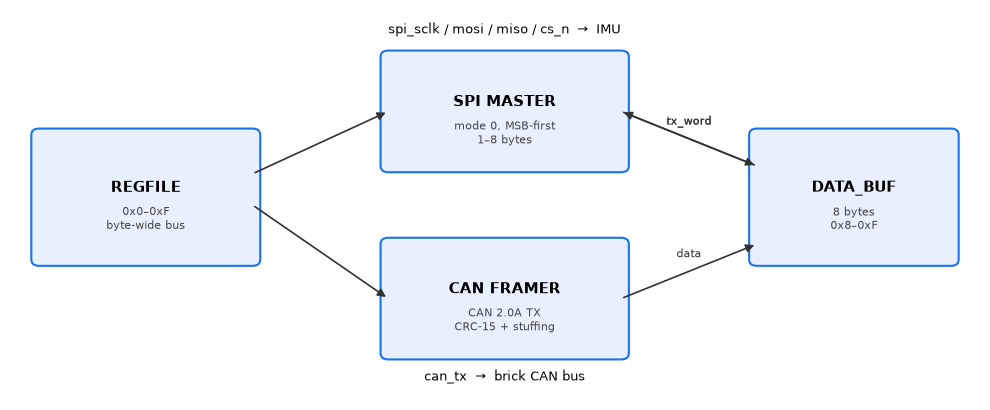

In [2]:
import matplotlib
import os as _os
_os.environ["MPLBACKEND"] = "Agg"
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.axis("off")

def box(x, y, w, h, label, sub=""):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08",
                 facecolor="#e8f0fe", edgecolor="#1a73e8", linewidth=1.5))
    ax.text(x + w/2, y + h/2 + 0.12, label, ha="center", va="center", fontsize=11, weight="bold")
    if sub:
        ax.text(x + w/2, y + h/2 - 0.28, sub, ha="center", va="center", fontsize=8, color="#444")

def arrow(x1, y1, x2, y2, label=""):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12,
                 color="#333", linewidth=1.2))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.18, label, ha="center", fontsize=8, color="#333")

box(0.3, 1.8, 2.2, 1.6, "REGFILE", "0x0–0xF\nbyte-wide bus")
box(3.9, 3.0, 2.4, 1.4, "SPI MASTER", "mode 0, MSB-first\n1–8 bytes")
box(3.9, 0.6, 2.4, 1.4, "CAN FRAMER", "CAN 2.0A TX\nCRC-15 + stuffing")
box(7.7, 1.8, 2.0, 1.6, "DATA_BUF", "8 bytes\n0x8–0xF")
arrow(2.5, 2.9, 3.9, 3.7); arrow(2.5, 2.5, 3.9, 1.3)
arrow(6.3, 3.7, 7.7, 3.0, "tx_word"); arrow(6.3, 1.3, 7.7, 2.0, "data")
arrow(7.7, 3.0, 6.3, 3.7, "rx_word")
ax.text(5.1, 4.7, "spi_sclk / mosi / miso / cs_n  →  IMU", ha="center", fontsize=9)
ax.text(5.1, 0.25, "can_tx  →  brick CAN bus", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig("block_diagram.png", dpi=150)
print("wrote block_diagram.png")


## 4. RTL

The design is three files, ~400 lines total. The most interesting module is the CAN framer — CRC computed combinatorially at frame start, then a bit-tick FSM applies stuffing on the fly:


In [3]:
!wc -l rtl/*.v && echo "----- can_framer.v (transmit FSM) -----" && sed -n '/S_SEND: begin/,/S_DONE: begin/p' rtl/can_framer.v | head -50


  153 rtl/brick_sensor_if.v
  160 rtl/can_framer.v
  121 rtl/spi_master.v
  434 total
----- can_framer.v (transmit FSM) -----
                S_SEND: begin
                    if (div_cnt == bitdiv_i) begin
                        div_cnt <= 8'd0;
                        if (ptr < raw_len) begin
                            b = frame_raw[raw_len-1-ptr];
                            if (run == 3'd5) begin
                                // insert stuff bit (complement), don't advance ptr.
                                // The receiver discards the stuff bit before
                                // run-counting, so reset the counter here too.
                                tx_o     <= ~last_bit;
                                run      <= 3'd0;
                            end else begin
                                tx_o <= b;
                                if (b == last_bit)
                                    run <= run + 3'd1;
                                else begin
           

Full sources are in `rtl/`: `brick_sensor_if.v` (top + register file), `spi_master.v`, `can_framer.v`.


## 5. Python golden model

`golden/can_golden.py` builds the exact transmitted bitstream for any (ID, DLC, data) triple: header + CRC-15 + bit-stuffing + trailer. It is the reference the RTL is checked against, bit for bit. First, a functional check of the model itself — the CRC residue property (recomputing the CRC over data+received-CRC must give zero) and a stuff/destuff round-trip over 5000 random frames:


In [4]:
import sys; sys.path.insert(0, "golden")
from can_golden import crc15, build_can_frame, count_stuff_bits
import random
random.seed(7)
for _ in range(5000):
    cid = random.randrange(2048); dlc = random.randrange(9)
    data = [random.randrange(256) for _ in range(dlc)]
    raw = [0] + [(cid >> i) & 1 for i in range(10, -1, -1)] + [0,0,0] + [(dlc >> i) & 1 for i in range(3,-1,-1)]
    for byte in data: raw += [(byte >> i) & 1 for i in range(7,-1,-1)]
    c = crc15(raw)
    full = raw + [(c >> i) & 1 for i in range(14,-1,-1)]
    assert crc15(full) == 0, "CRC residue"
    bits = build_can_frame(cid, dlc, data)
    out=[]; last=None; run=0; skip=False
    for b in bits[:-13]:
        if skip:
            assert b != last; skip=False; last=None; run=0; continue
        if b==last: run+=1
        else: last,run=b,1
        out.append(b)
        if run==5: skip=True
    assert out == full and not skip
print("golden model OK: 5000 random frames, CRC residue + stuff/destuff round-trip")


golden model OK: 5000 random frames, CRC residue + stuff/destuff round-trip


Now let's look at one concrete frame — ID `0x2A5`, 8 data bytes — and visualize the transmitted waveform, with stuff bits highlighted. (Plotted from the golden model; §6 proves the RTL emits this exact bitstream.)


ID=0x2A5 DLC=8 data=['0x0', '0x0', '0xff', '0xff', '0x0', '0x0', '0xff', '0xff']
unstuffed frame: 98 bits, transmitted: 123 bits (12 stuff bits + 13 trailer bits)
wrote can_waveform.png


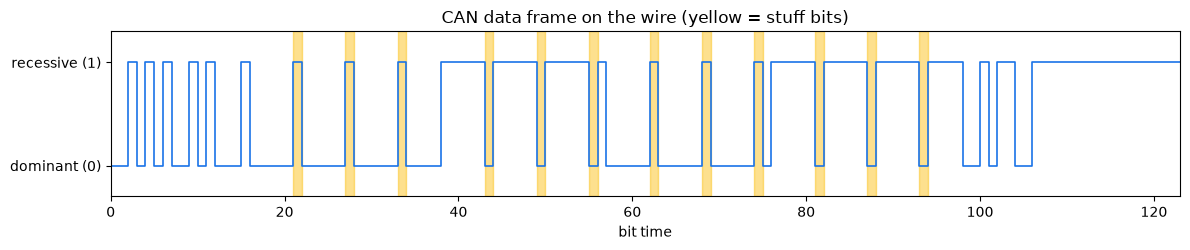

In [5]:
import matplotlib
import os as _os
_os.environ["MPLBACKEND"] = "Agg"
import matplotlib.pyplot as plt

can_id, dlc, data = 0x2A5, 8, [0x00,0x00,0xFF,0xFF,0x00,0x00,0xFF,0xFF]  # stuff-bit-rich pattern
bits = build_can_frame(can_id, dlc, data)
raw_len = 34 + 8*dlc
print(f"ID=0x{can_id:03X} DLC={dlc} data={[hex(b) for b in data]}")
print(f"unstuffed frame: {raw_len} bits, transmitted: {len(bits)} bits "
      f"({count_stuff_bits(can_id, dlc, data)} stuff bits + 13 trailer bits)")

# locate stuff bits (0-based transmitted positions) by re-running the stuffer
def stuff_positions(can_id, dlc, data):
    from can_golden import crc15
    raw=[0]+[(can_id>>i)&1 for i in range(10,-1,-1)]+[0,0,0]+[(dlc>>i)&1 for i in range(3,-1,-1)]
    for byte in data: raw += [(byte>>i)&1 for i in range(7,-1,-1)]
    c=crc15(raw); full=raw+[(c>>i)&1 for i in range(14,-1,-1)]
    pos=[]; last=None; run=0; idx=0
    for b in full:
        idx+=1
        if b==last: run+=1
        else: last,run=b,1
        if run==5:
            pos.append(idx)  # stuff bit is the next transmitted bit (0-based)
            idx+=1; last=None; run=0
    return pos

spos = set(stuff_positions(can_id, dlc, data))
fig, ax = plt.subplots(figsize=(12, 2.6))
xs, ys = [], []
for i, b in enumerate(bits):
    xs += [i, i+1]; ys += [b, b]
ax.plot(xs, ys, color="#1a73e8", linewidth=1.2)
for p in sorted(spos):
    ax.axvspan(p, p+1, color="#fbbc04", alpha=0.45)
ax.set_xlim(0, len(bits)); ax.set_ylim(-0.3, 1.3)
ax.set_yticks([0,1]); ax.set_yticklabels(["dominant (0)", "recessive (1)"])
ax.set_xlabel("bit time"); ax.set_title("CAN data frame on the wire (yellow = stuff bits)")
plt.tight_layout(); plt.savefig("can_waveform.png", dpi=150)
print("wrote can_waveform.png")


![CAN waveform](can_waveform.png)

## 6. Simulation — cocotb vs. the golden model

**Verification methodology:** a bit-exact Python golden model of the CAN framer (§5), differential testing of the RTL against it (seeded-random frames plus directed edge cases), then synthesis against the Sky130 PDK (§7). The testbench (`tb/tb_brick_sensor_if.v`) instantiates the DUT with MISO looped back to MOSI, so the SPI tests verify full-duplex shifting with no external slave model. `tb/test_sensor_if.py` + `tb/test_sensor_if_ext.py` drive the register bus and check:

| Test | What it proves |
|------|---------------|
| `test_spi_loopback` | 8-byte loopback: RX buffer == TX buffer; busy/done status; W1C clear |
| `test_spi_short_len` | 3-byte transfer shifts only 3 bytes; CS_N deasserts |
| `test_spi_len_sweep` | Loopback for every length 1–8, plus len=0 clamped to 8 |
| `test_can_frame_basic` | Full TX bitstream == golden model, bit for bit (ID 0x2A5, DLC 8) |
| `test_can_frame_stuffing` | Worst-case pattern (ID 0x7FF, eight 0xFF bytes → 15 stuff bits) still matches |
| `test_can_short_dlc` | DLC=2: shorter payload, CRC over fewer bytes |
| `test_can_randomized` | 40 seeded-random (ID, DLC, data) frames vs the golden model |
| `test_can_dlc_sweep` | DLC 0–8, including the empty-payload frame |
| `test_can_id_edges` | ID 0x000 and 0x7FF extremes |
| `test_can_dlc_clamp` | Programmed DLC=15 is clamped to 8 data bytes |
| `test_busy_reject` | Start-while-busy is ignored (SPI and CAN): no restart, no hang |
| `test_reset_mid_transfer` | Async reset mid-transfer clears busy, idles pins, block recovers |
| `test_back_to_back` | SPI → CAN → SPI with no idle gaps |

The CAN tests sample `can_tx` mid-bit after the SOF falling edge and diff against the golden bitstream — any single-bit error in framing, CRC, or stuffing fails loudly.


![Verification summary](verification_summary.png)

*Evaluation is layered. The golden model is checked for internal consistency first; the RTL is then compared with that model, and directed cases cover protocol and control behavior that random frames may miss.*


In [6]:
!cd tb && make 2>&1 | tail -25


                                                            Async reset mid-SPI and mid-CAN: busy clears, block recovers.
476872.01ns INFO     cocotb.regression                  test_sensor_if_ext.test_reset_mid_transfer passed
476872.01ns INFO     cocotb.regression                  running test_sensor_if_ext.test_back_to_back (13/13)
                                                            SPI read then CAN transmit then SPI again, no idle gaps needed.
492293.01ns INFO     cocotb.regression                  test_sensor_if_ext.test_back_to_back passed
492293.01ns INFO     cocotb.regression                  ****************************************************************************************************
                                                        ** TEST                                        STATUS  SIM TIME (ns)  REAL TIME (s)  RATIO (ns/s) **
                                                        *********************************************************************

## 7. Synthesis — Yosys + SkyWater sky130

Synthesized for the SkyWater 130 nm HD standard-cell library (`sky130_fd_sc_hd`, TT corner) exactly as it will be hardened for the Tiny Tapeout shuttle:


In [7]:
!cat synth.ys


# synth.ys — Yosys synthesis for brick_sensor_if, SkyWater sky130_fd_sc_hd (TT corner)
# Template: @PDK_LIB@ is substituted with the path to sky130_fd_sc_hd__tt_100C_1v80.lib
#   (see run_synth.sh, which locates it via volare)
#   (see run_synth.sh, which locates it via volare)
read_verilog -sv rtl/spi_master.v rtl/can_framer.v rtl/brick_sensor_if.v
hierarchy -check -top brick_sensor_if
flatten
proc; opt; fsm; opt; memory; opt; techmap; opt
dfflibmap -liberty @PDK_LIB@
abc -liberty @PDK_LIB@ -D 10000
clean
opt
stat
write_verilog -noattr synth/netlist.v


In [8]:
import os, glob
libs = glob.glob(os.path.expanduser("~/.volare/**/sky130_fd_sc_hd__tt_100C_1v80.lib"), recursive=True)
assert libs, "PDK liberty not found -- did the setup cell (§2) finish?"
PDK_LIB = libs[0]
print("PDK_LIB =", PDK_LIB)
open("synth/synth_run.ys", "w").write(open("synth.ys").read().replace("@PDK_LIB@", PDK_LIB))
!mkdir -p synth && yosys synth/synth_run.ys 2>&1 | tee synth/synth.log | tail -45


PDK_LIB = /home/hatch/.volare/volare/sky130/versions/c6d73a35f524070e85faff4a6a9eef49553ebc2b/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_100C_1v80.lib


     sky130_fd_sc_hd__nand2_1      463
     sky130_fd_sc_hd__nand2b_1      18
     sky130_fd_sc_hd__nand3_1       70
     sky130_fd_sc_hd__nand3b_1       2
     sky130_fd_sc_hd__nand4_1       15
     sky130_fd_sc_hd__nand4bb_1      1
     sky130_fd_sc_hd__nor2_1       370
     sky130_fd_sc_hd__nor2b_1        5
     sky130_fd_sc_hd__nor3_1        39
     sky130_fd_sc_hd__nor3b_1        1
     sky130_fd_sc_hd__nor4_1        12
     sky130_fd_sc_hd__nor4b_1        2
     sky130_fd_sc_hd__nor4bb_1       1
     sky130_fd_sc_hd__o2111ai_1      1
     sky130_fd_sc_hd__o211a_1        1
     sky130_fd_sc_hd__o211ai_1      11
     sky130_fd_sc_hd__o21a_1        22
     sky130_fd_sc_hd__o21ai_0      349
     sky130_fd_sc_hd__o21ba_1        1
     sky130_fd_sc_hd__o21bai_1       3
     sky130_fd_sc_hd__o221a_1        1
     sky130_fd_sc_hd__o221ai_1       6
     sky130_fd_sc_hd__o22a_1         1
     sky130_fd_sc_hd__o22ai_1       10
     sky130_fd_sc_hd__o31a_1         2
     sky130_fd_sc_hd__o31

### Results

The next cell parses the Yosys report into a PPA table and a cell-area breakdown:


standard cells : 3461
flip-flops     : 459
cell area      : 30,546 um^2  (0.0305 mm^2, pre-place)


wrote synth_cells.png


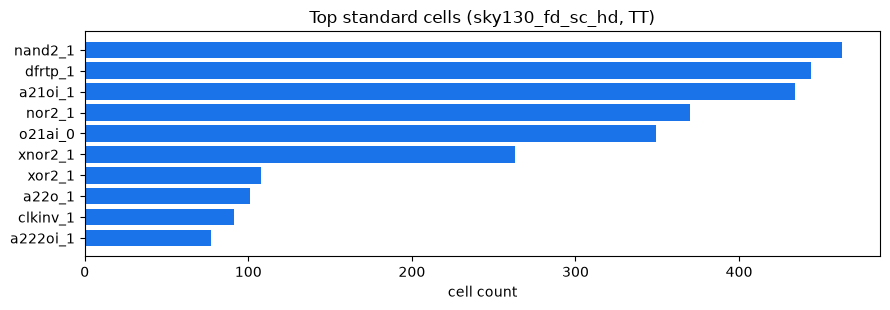

In [9]:
import re, glob
txt = open("synth/synth.log").read()
sec = re.split(r"\d+\. Printing statistics", txt)[1]

# cell histogram from the stat section
cells = re.findall(r"^\s+(sky130_fd_sc_hd__\w+)\s+(\d+)\s*$", sec, re.M)
ncells = sum(int(c) for _, c in cells)
nff = sum(int(c) for n, c in cells if re.search(r"__(df|sdfr|edf|sdf)\w*_", n + "_"))

# cell area from the liberty file (first area value at cell scope)
lib = PDK_LIB
areas, cur = {}, None
for line in open(lib):
    m = re.match(r'\s*cell\s*\(\s*"?(sky130_fd_sc_hd__\w+)"?\s*\)', line)
    if m:
        cur = m.group(1); continue
    m = re.match(r'^        area\s*:\s*([\d.]+)', line)
    if m and cur and cur not in areas:
        areas[cur] = float(m.group(1)); cur = None
area = sum(areas.get(n, 0.0) * int(c) for n, c in cells)

print(f"standard cells : {ncells}")
print(f"flip-flops     : {nff}")
print(f"cell area      : {area:,.0f} um^2  ({area/1e6:.4f} mm^2, pre-place)")

import matplotlib
import os as _os
_os.environ["MPLBACKEND"] = "Agg"
import matplotlib.pyplot as plt
top = sorted(((n, int(c)) for n, c in cells), key=lambda x: -x[1])[:10]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh([n.replace("sky130_fd_sc_hd__", "") for n, _ in reversed(top)],
        [c for _, c in reversed(top)], color="#1a73e8")
ax.set_xlabel("cell count"); ax.set_title("Top standard cells (sky130_fd_sc_hd, TT)")
plt.tight_layout(); plt.savefig("synth_cells.png", dpi=150)
print("wrote synth_cells.png")


![synth cells](synth_cells.png)

### What the numbers mean

- The whole block (register file + SPI master + CAN framer) synthesizes to **3,461 standard cells, 459 flip-flops, 0.031 mm²** of cell area (pre-place, TT corner) — the CAN framer's parallel frame assembler dominates, as expected.
- No latches inferred, no combinatorial loops, no memories; the design is fully synchronous to one clock with an asynchronous active-low reset, which is exactly what the Tiny Tapeout hardening flow wants.
- The block targets 100 MHz operation (10 ns period): at 100 MHz sysclk the dividers deliver the specified 10 MHz SPI and 1 Mbps CAN rates. `abc` was given a 10 ns delay target (`-D 10000` in `synth.ys`); ABC does not report an achieved critical-path delay in this flow, so 100 MHz remains a synthesis target, not a closed timing result. (Full sign-off STA with OpenSTA is future work — the numbers here are synthesis estimates, not sign-off timing.)
- Area note: 3,461 standard cells is about 3x what fits comfortably in one Tiny Tapeout tile (~1k cells). The parallel assembler was chosen for clarity and verifiability here; the planned Tiny Tapeout hardening swaps it for a bit-serial shift-register framer (same golden model, same tests), targeting a single-tile fit.

## 8. From notebook to silicon

The same `rtl/` in this directory will be hardened for **Tiny Tapeout TTSKY26d** (deadline Nov 30, 2026) behind a Tiny Tapeout byte-wide wrapper (`ui_in`/`uo_out`/`uio_*`); the wrapper and `info.yaml` are tracked separately and not part of this notebook submission. Two hardening tasks are planned: (1) a bit-serial rewrite of the CAN frame assembler targeting a single-tile fit (§7 area note), re-verified against the identical golden model and cocotb suite; (2) re-running the CAN-frame comparisons against the post-synthesis netlist after OpenLane.

## 9. Reproducibility

Tool versions used for every number in this notebook:


In [10]:
!yosys -V; iverilog -V | head -1; python3 -c "import cocotb; print('cocotb', cocotb.__version__)"; volare --version 2>/dev/null; echo "---"; ls -R . | head -30


Yosys 0.33 (git sha1 2584903a060)
Icarus Verilog version 12.0 (stable) ()


cocotb 2.1.0


Volare v0.20.6 ©2022-2025 Efabless Corporation

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this program except in compliance with the License.
You may obtain a copy of the License at

    http://www.apache.org/licenses/LICENSE-2.0

Unless required by applicable law or agreed to in writing, software
distributed under the License is distributed on an "AS IS" BASIS,
WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
See the License for the specific language governing permissions and
limitations under the License.
---
.:
LICENSE
README.md
block_diagram.png
brick_sensor_if.ipynb
can_waveform.png
golden
rtl
run_synth.sh
synth
synth.ys
synth_cells.png
tb

./golden:
__pycache__
can_golden.py

./golden/__pycache__:
can_golden.cpython-312-pytest-9.1.1.pyc
can_golden.cpython-312.pyc

./rtl:
brick_sensor_if.v
can_framer.v
spi_master.v

./synth:
generic_flat.log
generic_synth.log


## 8. Design decisions, limitations, and next steps

Three decisions define the implementation.

1. **A byte-wide register interface.** Software configures transfers and polls sticky status flags through a small register file. This keeps integration simple for an MCU or scan controller, at the cost of serialization overhead that a streaming interface would avoid.
2. **Parallel frame assembly before transmission.** The CAN framer constructs the frame and CRC before the bit-level transmitter applies stuffing. This makes the transmitted bitstream deterministic and straightforward to compare with the Python model. The cost is area: the frame assembler is the largest part of the design.
3. **A transmit-only CAN scope.** The block generates CAN 2.0A data frames for a sensor uplink. It does not receive frames or implement arbitration, acknowledgement, error frames, or bus-off recovery. That narrower scope is deliberate for this application, but it also defines the main functional limitation.

The evaluation has three further limits. First, all functional evidence is from simulation; the block has not yet been measured on FPGA or silicon. Second, the synthesis numbers are pre-layout Yosys results, not post-route timing, power, DRC, or LVS sign-off. Third, the SPI engine implements a generic register-read transfer; device-specific IMU command sequences and data interpretation remain in software.

The next step is to harden the same RTL for Tiny Tapeout, including place-and-route and static timing analysis. A receive path and CAN error handling should be added only if the brick protocol becomes bidirectional; for a one-way sensor uplink, they would add area and verification burden without improving the stated function.


To reproduce: run the cells top to bottom. The setup cell (§2) installs everything on a fresh machine/Colab; simulation (§6) and synthesis (§7) re-run from the `rtl/`, `golden/`, `tb/`, `synth/` directories in this folder. The only network dependency is the one-time PDK download via Volare.

## References

- IEEE SSCS Code-a-Chip program: https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io
- SkyWater 130 nm PDK / Volare: https://github.com/efabless/volare
- Yosys open synthesis suite: https://yosyshq.net/yosys/
- cocotb: https://www.cocotb.org/
- CAN 2.0A frame format / CRC-15: ISO 11898-1; Bosch CAN Specification 2.0
- Prior art studied: ISSCC26 winning notebook "Opensource-ULP-CAN_Transceiver" (same repo, `ISSCC26/submitted_notebooks/`)
- BMI270 datasheet (Bosch Sensortec) — SPI mode-0 register protocol reference
- Tiny Tapeout: https://tinytapeout.com/

---
*License: Apache-2.0. The RTL, golden model, testbench, and this notebook are released under the Apache License 2.0 — see LICENSE.*
